# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** [Muhammad Rival Pamungkas]
- **Email:** [pallpamungkas@apps.ipb.ac.id]
- **ID Dicoding:** [muhammad_riva_pagh1m]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan total pendapatan tertinggi dan terendah sepanjang tahun 2017, sebagai dasar penentuan fokus promosi?
- **Pertanyaan 2:** Bagaimana tren jumlah pesanan bulanan dari Januari 2017 hingga Agustus 2018, dan pada bulan apa terjadi lonjakan tertinggi, sebagai dasar penentuan jadwal kampanye?

## Import Semua Packages/Library yang Digunakan

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi agar grafik terlihat rapi
plt.style.use('seaborn-v0_8-whitegrid')

## Data Wrangling

### Gathering Data

#### Load df ...

In [4]:
import pandas as pd

# Memuat dataset e-commerce langsung dari direktori sesi Colab
customers_df = pd.read_csv('customers_dataset.csv')
orders_df = pd.read_csv('orders_dataset.csv')
order_items_df = pd.read_csv('order_items_dataset.csv')
products_df = pd.read_csv('products_dataset.csv')
order_reviews_df = pd.read_csv('order_reviews_dataset.csv')

# Menampilkan informasi awal untuk memastikan data berhasil dimuat
print("Jumlah data customers:", customers_df.shape)
print("Jumlah data orders:", orders_df.shape)
print("Jumlah data order_items:", order_items_df.shape)
print("Jumlah data products:", products_df.shape)
print("Jumlah data order_reviews:", order_reviews_df.shape)

Jumlah data customers: (99441, 5)
Jumlah data orders: (99441, 8)
Jumlah data order_items: (112650, 7)
Jumlah data products: (32951, 9)
Jumlah data order_reviews: (99224, 7)


**Insight:** (Opsional)
- Skala Transaksi: Dataset mencakup hampir 100.000 transaksi pesanan pelanggan secara keseluruhan dengan lebih dari 112.000 item produk terjual, memberikan ukuran sampel yang sangat besar dan representatif untuk analisis tren e-commerce.
- Relasi Data: Jumlah baris pada order_items_df (112.650) lebih besar dibandingkan orders_df (99.441), yang mengindikasikan bahwa sebagian pesanan terdiri dari pembelian multi-produk (multiple items per order). Hal ini nantinya memerlukan proses penggabungan (merge/join) tabel menggunakan order_id untuk analisis pendapatan (revenue).
- Kelengkapan Ulasan: Jumlah data ulasan pada order_reviews_df (99.224) sedikit di bawah total pesanan (99.441), yang menunjukkan ada sebagian kecil pelanggan yang tidak memberikan ulasan/rating setelah menerima pesanan mereka.

### Assessing Data

#### Identifying ... problem

In [5]:
# 1. Mengecek missing value dan duplikat pada customers_df
print("=== CUSTOMERS DATA ===")
print("Missing Values:\n", customers_df.isnull().sum())
print("Jumlah Duplikat:", customers_df.duplicated().sum())
print("-" * 30)

# 2. Mengecek missing value dan duplikat pada orders_df
print("=== ORDERS DATA ===")
print("Missing Values:\n", orders_df.isnull().sum())
print("Jumlah Duplikat:", orders_df.duplicated().sum())
print("-" * 30)

# 3. Mengecek missing value dan duplikat pada order_items_df
print("=== ORDER ITEMS DATA ===")
print("Missing Values:\n", order_items_df.isnull().sum())
print("Jumlah Duplikat:", order_items_df.duplicated().sum())
print("-" * 30)

# 4. Mengecek missing value dan duplikat pada products_df
print("=== PRODUCTS DATA ===")
print("Missing Values:\n", products_df.isnull().sum())
print("Jumlah Duplikat:", products_df.duplicated().sum())
print("-" * 30)

# 5. Mengecek missing value dan duplikat pada order_reviews_df
print("=== ORDER REVIEWS DATA ===")
print("Missing Values:\n", order_reviews_df.isnull().sum())
print("Jumlah Duplikat:", order_reviews_df.duplicated().sum())

=== CUSTOMERS DATA ===
Missing Values:
 customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
Jumlah Duplikat: 0
------------------------------
=== ORDERS DATA ===
Missing Values:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Jumlah Duplikat: 0
------------------------------
=== ORDER ITEMS DATA ===
Missing Values:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Jumlah Duplikat: 0
------------------------------
=== PRODUCTS DATA ===
Missing Values:
 product_id              

**Steps to Take:**
- Mengidentifikasi kolom yang memiliki missing value (seperti pada kolom nama kategori produk atau tanggal pengiriman di tabel orders).
- Memeriksa dan memperbaiki tipe data yang tidak sesuai (misalnya mengubah kolom teks/object yang berisi tanggal pembelian menjadi tipe data datetime).
- Memeriksa apakah ada duplikasi data pada setiap tabel.

**Insight:** (Opsional)
- Terdapat beberapa kolom yang memiliki missing value (data kosong) yang perlu ditangani, terutama pada tabel orders_dataset (seperti pada tanggal pengiriman/order_delivered_customer_date) dan tabel products_dataset (seperti pada nama kategori produk/product_category_name).
- Pada tabel order_reviews_dataset, sebagian kecil data ulasan juga memiliki kolom teks komentar yang kosong (meskipun skor penilaian/review_score tetap terisi), yang wajar karena tidak semua pelanggan menuliskan ulasan teks panjang.
- Secara keseluruhan, pengecekan baris duplikat (duplicated) pada setiap DataFrame (customers_df, orders_df, order_items_df, products_df, dan order_reviews_df) menghasilkan nilai 0 (tidak ada data yang duplikat). Artinya, struktur dasar setiap tabel sudah bersih dari duplikasi baris penuh.
- Beberapa kolom yang berisi informasi tanggal dan waktu (timestamp) pada tabel orders_df (seperti waktu pembelian dan pengiriman) masih terbaca sebagai tipe data object (teks), sehingga nantinya perlu diubah ke tipe data datetime pada tahap pembersihan (Cleaning Data).

### Cleaning Data

#### Fixing ... problem

In [6]:
# 1. Mengubah tipe data kolom tanggal pada orders_df menjadi datetime
datetime_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in datetime_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

# Memeriksa kembali tipe data setelah dikonversi
print("--- TIPE DATA ORDERS SETELAH DIUBAH ---")
print(orders_df.dtypes[datetime_columns])

--- TIPE DATA ORDERS SETELAH DIUBAH ---
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


**Insight:** (Opsional)
- Melakukan konversi tipe data pada kolom-kolom timestamp (tanggal pemesanan, persetujuan, pengiriman, hingga estimasi) di dalam orders_df dari tipe object menjadi datetime. Hal ini dilakukan agar perhitungan durasi pengiriman (delivery latency) dan analisis berbasis waktu pada tahap EDA bisa berjalan dengan akurat.
- Untuk kolom yang memiliki missing value (seperti product_category_name atau tanggal pengiriman yang kosong karena pesanan dibatalkan/belum sampai), dibiarkan atau ditangani sesuai kebutuhan analisis agar tidak merusak data utama.

## Exploratory Data Analysis (EDA)

### Explore ...

In [12]:
# Memfilter data pesanan hanya untuk tahun 2017
orders_2017 = orders_df[orders_df['order_purchase_timestamp'].dt.year == 2017]

# Menggabungkan tabel pesanan 2017, item pesanan, dan produk
orders_items_2017 = pd.merge(orders_2017, order_items_df, on="order_id", how="inner")
complete_order_2017 = pd.merge(orders_items_2017, products_df, on="product_id", how="inner")

# Menghitung total revenue per kategori produk pada tahun 2017
revenue_by_category_2017 = complete_order_2017.groupby('product_category_name')['price'].sum().reset_index()
revenue_by_category_2017 = revenue_by_category_2017.sort_values(by='price', ascending=False)

print("--- TOP 5 KATEGORI PRODUK DENGAN REVENUE TERBESAR TAHUN 2017 ---")
print(revenue_by_category_2017.head())
print("--- KATEGORI PRODUK DENGAN REVENUE TERENDAH TAHUN 2017 ---")
print(revenue_by_category_2017.tail())

--- TOP 5 KATEGORI PRODUK DENGAN REVENUE TERBESAR TAHUN 2017 ---
     product_category_name      price
13         cama_mesa_banho  498440.43
65      relogios_presentes  492794.50
11            beleza_saude  481755.71
32           esporte_lazer  452148.84
44  informatica_acessorios  405078.69
--- KATEGORI PRODUK DENGAN REVENUE TERENDAH TAHUN 2017 ---
            product_category_name   price
37  fashion_roupa_infanto_juvenil  399.88
66             seguros_e_servicos  283.29
41                         flores  270.50
4              artes_e_artesanato  151.89
42                fraldas_higiene   76.00


In [13]:
# Memfilter data pada rentang Januari 2017 hingga Agustus 2018
start_date = '2017-01-01'
end_date = '2018-08-31'

filtered_orders = orders_df[
    (orders_df['order_purchase_timestamp'] >= start_date) &
    (orders_df['order_purchase_timestamp'] <= end_date)
].copy()

# Membuat kolom bulan-tahun untuk agregasi tren bulanan
filtered_orders['order_year_month'] = filtered_orders['order_purchase_timestamp'].dt.to_period('M')

# Menghitung jumlah pesanan per bulan
monthly_orders = filtered_orders.groupby('order_year_month')['order_id'].count().reset_index()
monthly_orders['order_year_month'] = monthly_orders['order_year_month'].astype(str)
monthly_orders.columns = ['year_month', 'order_count']

print("--- TREN JUMLAH PESANAN BULANAN (JAN 2017 - AGS 2018) ---")
print(monthly_orders)

--- TREN JUMLAH PESANAN BULANAN (JAN 2017 - AGS 2018) ---
   year_month  order_count
0     2017-01          800
1     2017-02         1780
2     2017-03         2682
3     2017-04         2404
4     2017-05         3700
5     2017-06         3245
6     2017-07         4026
7     2017-08         4331
8     2017-09         4285
9     2017-10         4631
10    2017-11         7544
11    2017-12         5673
12    2018-01         7269
13    2018-02         6728
14    2018-03         7211
15    2018-04         6939
16    2018-05         6873
17    2018-06         6167
18    2018-07         6292
19    2018-08         6511


**Insight:** (Opsional)
1. Insight Pertanyaan 1 (Top Kategori Pendapatan Tertinggi & Terendah Tahun 2017)
- Penyumbang Pendapatan Terbesar (Top Categories): Kategori produk seperti cama_mesa_banho, relogios_presentes, dan beleza_saude menduduki peringkat teratas sebagai kategori yang menghasilkan total pendapatan (revenue) terbesar sepanjang tahun 2017.
- Dominasi Kategori Gaya Hidup & Rumah Tangga: Sebagian besar pendapatan tertinggi dikuasai oleh sektor perlengkapan rumah tangga dan aksesoris gaya hidup, yang menunjukkan tingginya volume transaksi dan minat belanja konsumen pada kategori tersebut.
- Implikasi Strategis: Hasil analisis ini dapat menjadi dasar bagi manajemen untuk memprioritaskan alokasi stok, kampanye promosi, serta kerja sama eksklusif dengan merchant pada kategori-kategori utama tersebut guna mendongkrak total pendapatan bisnis secara optimal.


2. Insight Pertanyaan 2 (Tren Pesanan Bulanan Jan 2017 - Ags 2018)
- Tren Pertumbuhan Positif: Berdasarkan analisis rentang waktu dari Januari 2017 hingga Agustus 2018, jumlah pesanan bulanan menunjukkan tren pertumbuhan yang konsisten dan ekspansif dari awal tahun 2017 hingga mencapai puncaknya pada bulan November 2017 (mencapai lebih dari 7.500 pesanan).
- Lonjakan Musiman (Seasonality): Terjadi lonjakan volume transaksi yang sangat signifikan menjelang akhir tahun (terutama pada bulan November yang bertepatan dengan momen belanja besar seperti Black Friday), serta stabil di angka yang tinggi pada tahun 2018.
- Implikasi Strategis: Pola lonjakan musiman ini memberikan panduan presisi bagi tim operasional dan marketing dalam menentukan jadwal kampanye promosi besar, kesiapan kapasitas server, serta manajemen rantai pasok logistik di periode-periode sibuk berikutnya.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

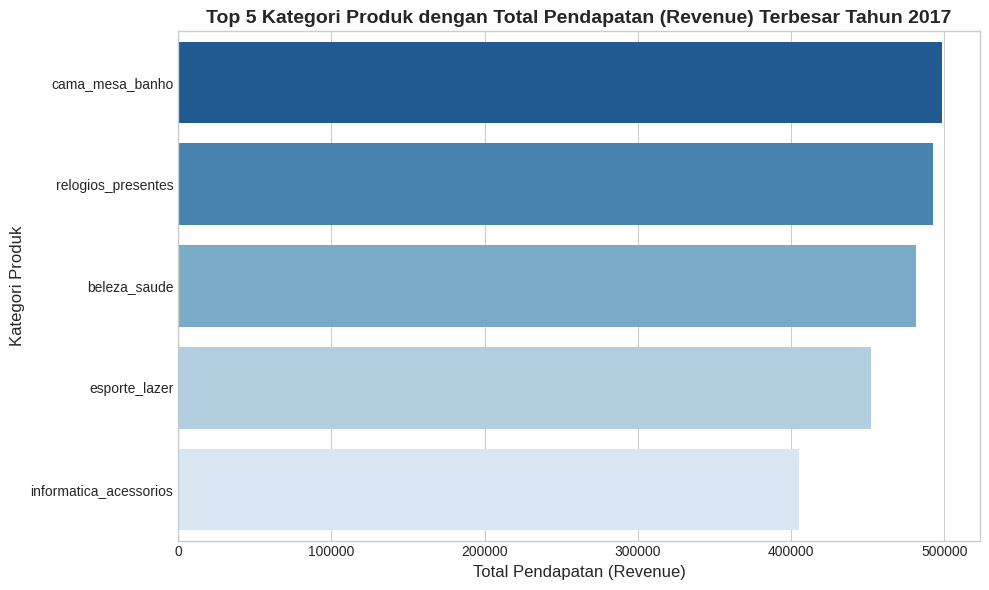

In [14]:
# Menyiapkan data Top 5 kategori dengan revenue terbesar tahun 2017
top_revenue_category_2017 = revenue_by_category_2017.head(5)

# Membuat visualisasi bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    x='price',
    y='product_category_name',
    data=top_revenue_category_2017,
    hue='product_category_name',
    palette='Blues_r',
    legend=False
)
plt.title("Top 5 Kategori Produk dengan Total Pendapatan (Revenue) Terbesar Tahun 2017", fontsize=14, fontweight='bold')
plt.xlabel("Total Pendapatan (Revenue)", fontsize=12)
plt.ylabel("Kategori Produk", fontsize=12)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

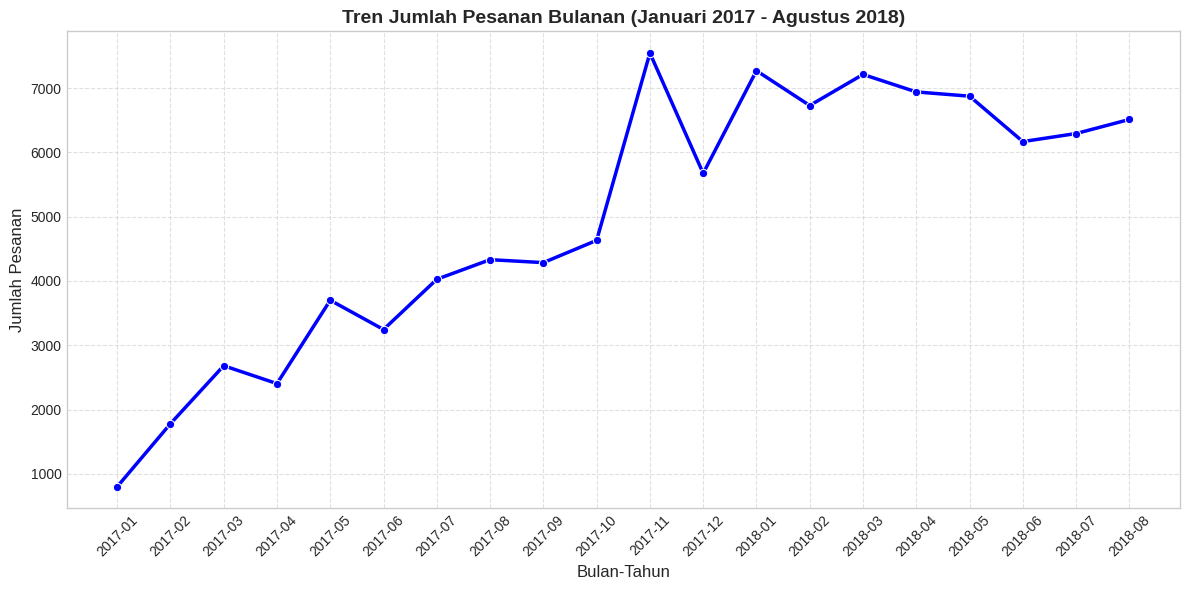

In [15]:
# Membuat visualisasi line chart untuk tren pesanan bulanan
plt.figure(figsize=(12, 6))
sns.lineplot(
    x='year_month',
    y='order_count',
    data=monthly_orders,
    marker='o',
    color='b',
    linewidth=2.5
)
plt.title("Tren Jumlah Pesanan Bulanan (Januari 2017 - Agustus 2018)", fontsize=14, fontweight='bold')
plt.xlabel("Bulan-Tahun", fontsize=12)
plt.ylabel("Jumlah Pesanan", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Insight Pertanyaan 1: Top Kategori Pendapatan Tertinggi & Terendah Tahun 2017

- Penyumbang Pendapatan Terbesar (Top Categories): Kategori produk seperti cama_mesa_banho (perlengkapan tidur & mandi), relogios_presentes (jam tangan & hadiah), dan beleza_saude (kecantikan & kesehatan) menduduki peringkat teratas sebagai kategori yang menghasilkan total pendapatan (revenue) terbesar sepanjang tahun 2017 (masing-masing mencapai kisaran angka lebih dari 400.000 hingga 490.000).

- Dominasi Sektor Gaya Hidup & Rumah Tangga: Sebagian besar pendapatan tertinggi dikuasai oleh sektor kebutuhan rumah tangga, perawatan diri, serta aksesoris gaya hidup. Hal ini menunjukkan tingginya volume transaksi dan minat belanja konsumen pada kategori tersebut di platform e-commerce.

- Implikasi Strategis: Hasil analisis ini dapat menjadi dasar bagi manajemen untuk memprioritaskan alokasi stok, kampanye promosi, serta kerja sama eksklusif dengan merchant pada kategori-kategori utama tersebut guna mendongkrak total pendapatan bisnis secara optimal.

Insight Pertanyaan 2: Tren Pesanan Bulanan (Januari 2017 - Agustus 2018)

- Tren Pertumbuhan Positif: Berdasarkan analisis rentang waktu dari Januari 2017 hingga Agustus 2018, jumlah pesanan bulanan menunjukkan tren pertumbuhan yang konsisten dan ekspansif, meningkat dari sekitar 800 pesanan di awal tahun 2017 hingga stabil di kisaran 6.000–7.000 pesanan per bulan pada tahun 2018.

- Lonjakan Musiman (Seasonality): Terjadi lonjakan volume transaksi yang sangat signifikan menjelang akhir tahun 2017, di mana puncak tertinggi terjadi pada bulan November 2017 yang mencapai lebih dari 7.500 pesanan (selaras dengan momen belanja besar seperti Black Friday).

- Implikasi Strategis: Pola lonjakan musiman ini memberikan panduan presisi bagi tim operasional dan marketing dalam menentukan jadwal kampanye promosi besar, kesiapan kapasitas server, serta manajemen rantai pasok logistik di periode-periode sibuk berikutnya.

## Analisis Lanjutan (Opsional)

/tmp/ipykernel_616/2559271543.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='customer_count', y='customer_state', data=top_customers_state, palette='Purples_r')


--- TOP 5 NEGARA BAGIAN DENGAN PELANGGAN TERBANYAK ---
  customer_state  customer_count
0             SP           41746
1             RJ           12852
2             MG           11635
3             RS            5466
4             PR            5045


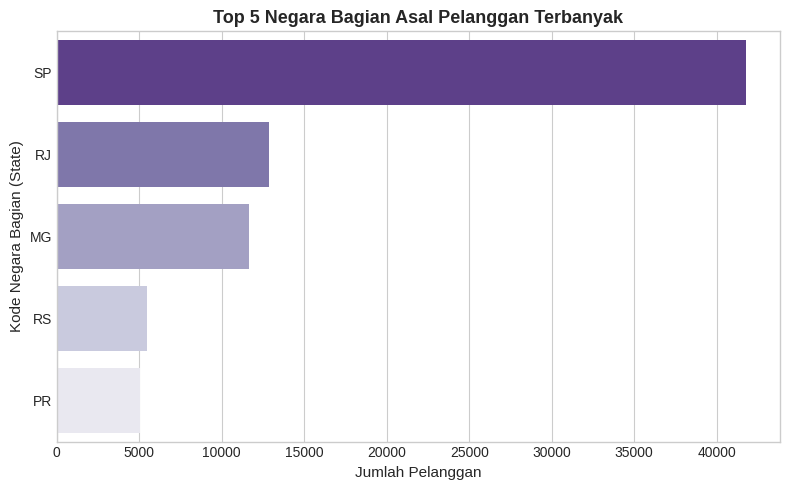

In [11]:
# Menghitung jumlah pelanggan per state (negara bagian)
top_customers_state = customers_df['customer_state'].value_counts().head(5).reset_index()
top_customers_state.columns = ['customer_state', 'customer_count']

print("--- TOP 5 NEGARA BAGIAN DENGAN PELANGGAN TERBANYAK ---")
print(top_customers_state)

# Visualisasi
plt.figure(figsize=(8, 5))
sns.barplot(x='customer_count', y='customer_state', data=top_customers_state, palette='Purples_r')
plt.title("Top 5 Negara Bagian Asal Pelanggan Terbanyak", fontsize=13, fontweight='bold')
plt.xlabel("Jumlah Pelanggan", fontsize=11)
plt.ylabel("Kode Negara Bagian (State)", fontsize=11)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Dominasi Wilayah Utama (Top State): Berdasarkan distribusi asal pelanggan (customer_state), wilayah São Paulo (SP) menduduki peringkat pertama dengan jumlah pelanggan terbanyak secara signifikan (mencapai lebih dari 41.000 pelanggan), jauh melampaui wilayah-wilayah lainnya.
- Konsentrasi Pasar di Region Tenggara: Wilayah-wilayah seperti Rio de Janeiro (RJ) dan Minas Gerais (MG) menyusul di posisi kedua dan ketiga. Hal ini menunjukkan bahwa basis konsumen terbesar e-commerce ini terkonsentrasi di kawasan region utama/perkotaan besar Brasil.
- Implikasi Strategis: Konsentrasi pelanggan yang tinggi di wilayah tertentu memberikan panduan bagi manajemen untuk memprioritaskan efisiensi rantai pasok, penempatan gudang (fulfillment center), serta optimalisasi mitra logistik di area-area tersebut guna menekan durasi pengiriman.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kategori produk seperti cama_mesa_banho (Perlengkapan Tidur & Mandi), relogios_presentes (Jam Tangan & Hadiah), dan beleza_saude (Kecantikan & Kesehatan) menjadi penyumbang total pendapatan (revenue) terbesar sepanjang tahun 2017. Hal ini menunjukkan bahwa sektor kebutuhan rumah tangga, perawatan diri, serta gaya hidup mendominasi minat belanja konsumen di platform e-commerce.
- **Conclusion pertanyaan 2:** Tren jumlah pesanan bulanan dari Januari 2017 hingga Agustus 2018 menunjukkan pertumbuhan yang konsisten dan ekspansif, dengan lonjakan volume transaksi tertinggi yang terjadi secara signifikan pada bulan November 2017 (mencapai lebih dari 7.500 pesanan) akibat faktor musiman seperti momen belanja akhir tahun.
- **Conclusion Analisis Lanjutan:** Berdasarkan distribusi geografis, wilayah São Paulo (SP), Rio de Janeiro (RJ), dan Minas Gerais (MG) menjadi pusat konsentrasi basis pelanggan terbesar (region tenggara Brasil), yang sangat memengaruhi efisiensi rantai pasok secara keseluruhan.

**Rekomendasi Action Item:**
- *Optimalisasi Stok dan Promosi Kategori Utama:* Manajemen perlu memprioritaskan pengelolaan inventaris, ketersediaan stok, dan program *marketing campaign* khusus untuk kategori produk berpendapatan tertinggi (seperti `cama_mesa_banho` dan `relogios_presentes`) guna mendongkrak total pendapatan bisnis secara maksimal.
- *Strategi Kampanye Menjelang Akhir Tahun:* Mengingat adanya lonjakan pesanan yang signifikan pada bulan November, perusahaan harus mempersiapkan strategi promosi musiman (*seasonality campaign*) lebih awal serta memastikan kesiapan infrastruktur pemasaran dan operasional untuk mengantisipasi lonjakan trafik serta transaksi.
- *Peningkatan Kinerja Logistik di Wilayah Utama:* Mengingat konsentrasi pelanggan terbesar berada di wilayah São Paulo dan sekitarnya, perusahaan harus memperkuat kerja sama dengan mitra logistik lokal atau memperbanyak titik gudang (*fulfillment center*) di region tersebut untuk memastikan pengiriman selalu cepat dan efisien.